In [1]:
#Importação de bibliotecas
import geopandas as gpd
import libpysal
import esda
import matplotlib.pyplot as plt
from splot.esda import moran_scatterplot, lisa_cluster
import numpy as np
#Carregar o GeoPackage do IVE
caminho_ive = r'C:\Users\Waxl_Sampaio\Documents\Artigo_previa\Escolas_Aponds\Timon_Apond_IVE_4D_Final.gpkg'
gdf_ive = gpd.read_file(caminho_ive)
# Remover qualquer NaN que possa ter sobrado
gdf_ive = gdf_ive.dropna(subset=['IVE_FINAL_4D'])
print(f"Dados carregados: {len(gdf_ive)} Áreas de Ponderação")

# Matriz de Pesos Espaciais (Contiguidade "Queen")
# Queen
w = libpysal.weights.Queen.from_iterable(gdf_ive.geometry)
w.transform = 'R'
# 3. Calcular o I de Moran Global
variavel = 'IVE_FINAL_4D'
moran_global = esda.Moran(gdf_ive[variavel], w, permutations=999)
print(f" Resultados do I de Moran Global para o IVE 4D:")
print(f" Índice de Moran (I): {moran_global.I:.4f}")
print(f" Valor-p (p_sim): {moran_global.p_sim:.4f}")
print(f" Z-score: {moran_global.z_sim:.4f}")
if moran_global.p_sim < 0.05:
    tipo = "AGLOMERADO (Cluster)" if moran_global.I > 0 else "DISPERSÃO"
    print(f" CONCLUSÃO: Padrão espacial de {tipo} estatisticamente significativo.")
else:
    print(f" CONCLUSÃO: Padrão espacial ALEATÓRIO (sem autocorrelação significativa).")

Dados carregados: 9 Áreas de Ponderação
 Resultados do I de Moran Global para o IVE 4D:
 Índice de Moran (I): -0.0558
 Valor-p (p_sim): 0.3070
 Z-score: 0.5218
 CONCLUSÃO: Padrão espacial ALEATÓRIO (sem autocorrelação significativa).


Distribuição dos Clusters Locais:
LISA_CLUSTER
Não Significativo    9
Name: count, dtype: int64


C:\Users\Waxl_Sampaio\AppData\Local\Programs\Python\Python314\Lib\site-packages\splot\_viz_esda_mpl.py:131: UserWarning: `p` is only used for plotting `esda.moran.Moran_Local`
or `Moran_Local_BV` objects
  warnings.warn(
C:\Users\Waxl_Sampaio\AppData\Local\Programs\Python\Python314\Lib\site-packages\spreg\diagnostics.py:620: ComplexWarning: Casting complex values to real discards the imaginary part
  ci_result = sqrt(max_eigval / min_eigval)


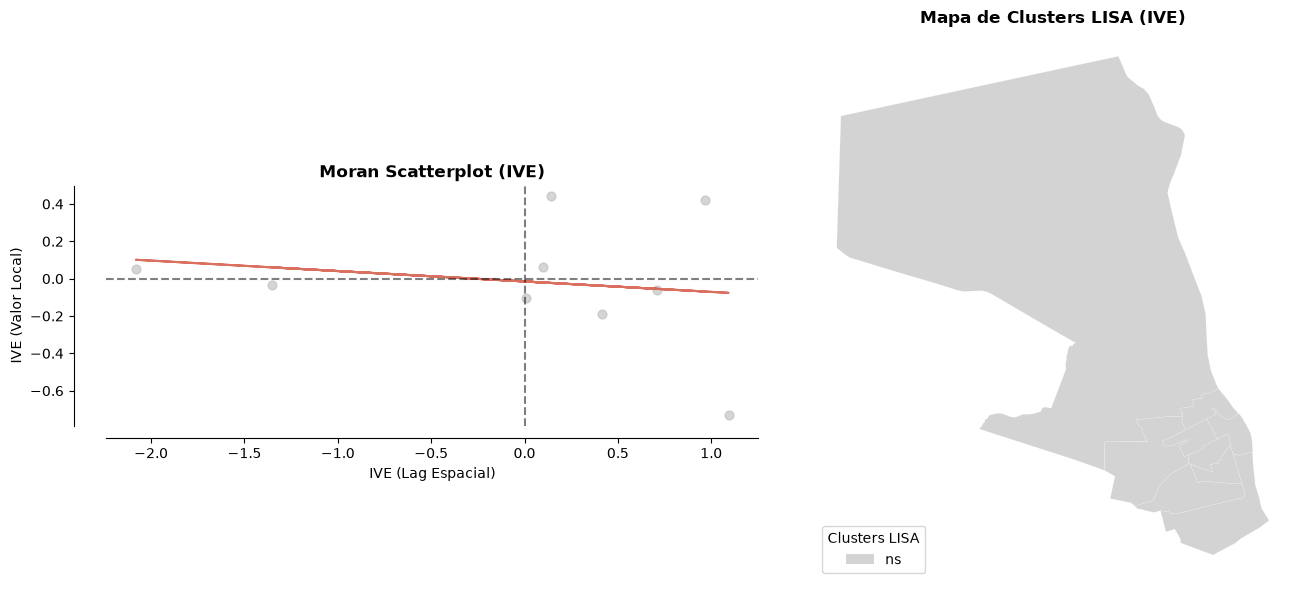

In [2]:
# 1. Calculo LISA
lisa = esda.Moran_Local(gdf_ive[variavel], w, permutations=999)
# 2. Adicionar resultados ao GeoDataFrame
gdf_ive['LISA_Q'] = lisa.q          # 1=HH, 2=LH, 3=LL, 4=HL
gdf_ive['LISA_P'] = lisa.p_sim      # Valor-p local
# traduzir os quadrantes em texto legível
def traduzir_lisa(q, p):
    if p < 0.05: # Apenas significativo se p < 0.05
        if q == 1: return 'High-High (Alta Vulnerabilidade)'
        if q == 2: return 'Low-High (Ilha de Baixa Vulnerabilidade)'
        if q == 3: return 'Low-Low (Baixa Vulnerabilidade)'
        if q == 4: return 'High-Low (Ilha de Alta Vulnerabilidade)'
    return 'Não Significativo'
gdf_ive['LISA_CLUSTER'] = gdf_ive.apply(lambda row: traduzir_lisa(row['LISA_Q'], row['LISA_P']), axis=1)

print("Distribuição dos Clusters Locais:")
print(gdf_ive['LISA_CLUSTER'].value_counts())
# 3. Visualização: Gráfico de Dispersão + Mapa LISA
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))
# Gráfico de Dispersão de Moran
moran_scatterplot(moran_global, p=0.05, ax=ax1)
ax1.set_title('Moran Scatterplot (IVE)', fontsize=12, fontweight='bold')
ax1.set_xlabel('IVE (Lag Espacial)', fontsize=10)
ax1.set_ylabel('IVE (Valor Local)', fontsize=10)
# Mapa de Cluster LISA
lisa_cluster(lisa, gdf_ive, p=0.05, ax=ax2, legend=True, 
             legend_kwds={'loc': 'lower left', 'title': 'Clusters LISA'})
ax2.set_title('Mapa de Clusters LISA (IVE)', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()